<a href="https://colab.research.google.com/github/Dr-AlaaKhamis/ISE518/blob/main/11_Diagnostic_analytics/Causal_Inference_and_Root_Cause_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Causal Inference and Root Cause Analysis
### ISE 518: Data Analytics for Reliability and Maintenance · Diagnostic Analytics

| | |
|---|---|
| **Course** | ISE 518, Industrial and Systems Engineering Department, KFUPM |
| **Instructor** | Dr. Alaa Khamis |
| **Tutorial prepared by** | **Ousman Khan**, AI for Smart Mobility Lab (AI4SM), KFUPM |
| **Companion** | Interactive tutorial page `index.html` (open it in any browser) |

**What you will learn**

1. Why association is not causation, and how a causal graph makes assumptions explicit.
2. The four DoWhy stages for effect estimation: **Model → Identify → Estimate → Refute**.
3. How a fitted structural causal model separates a fault's **origin** from its **propagated symptoms**,
   for a single abnormal request and for a persistent slowdown.

> **How to run.** In Google Colab, click the badge above and choose *Runtime → Run all*.
> Locally, install the packages in `requirements.txt` and open the notebook.
> The setup cell below installs anything missing and reads the data directly from the
> [ISE 518 GitHub repository](https://github.com/Dr-AlaaKhamis/ISE518/tree/main/11_Diagnostic_analytics),
> so no Google Drive access or local data files are needed (an internet connection is).

## 0 · Setup

Run this cell first. It works the same way in Colab and on your own machine.

In [ ]:
import importlib, subprocess, sys

# Install DoWhy and EconML only if they are missing (Colab ships without them).
for pkg in ["dowhy", "econml"]:
    if importlib.util.find_spec(pkg) is None:
        print(f"Installing {pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import logging, warnings

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

from dowhy import CausalModel, gcm

warnings.filterwarnings("ignore")                     # keep the outputs readable
logging.getLogger("dowhy").setLevel(logging.ERROR)
gcm.config.disable_progress_bars()
np.random.seed(42)

IN_COLAB = "google.colab" in sys.modules

# Data is read directly from the ISE 518 course repository on GitHub.
DATA_URL = ("https://raw.githubusercontent.com/Dr-AlaaKhamis/ISE518/main/"
            "11_Diagnostic_analytics/data/")
# Fallback: the original copy in the DoWhy repository.
BACKUP_URL = ("https://raw.githubusercontent.com/py-why/dowhy/main/"
              "docs/source/example_notebooks/")


def load_data(name):
    """Read a case-study CSV from the course repository (DoWhy copy as fallback)."""
    try:
        return pd.read_csv(DATA_URL + name)
    except Exception:
        return pd.read_csv(BACKUP_URL + name)


# Shared plotting style.
BLUE, NAVY, ORANGE, GRAY = "#00629B", "#002B49", "#E8710A", "#9AA5B1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

print(f"Running in {'Google Colab' if IN_COLAB else 'a local environment'}.")

## 1 · Motivation


## Two things move together.
## Does that mean one causes the other?

We regularly observe patterns:

- People who study more tend to achieve higher grades.
- Certain products sell more during particular seasons.
- Some system measurements rise whenever a failure occurs.

**Regression and many machine learning methods can learn these patterns
and use them to make predictions.**

But can we conclude that changing one variable will change the other?

**Association ≠ causation.**

---

### “Ice cream sales increase. Drownings increase.”

> **Should we reduce ice cream sales to prevent drownings?**

Hot weather can explain both:

- More people buy ice cream.
- More people go swimming, increasing exposure to drowning risk.

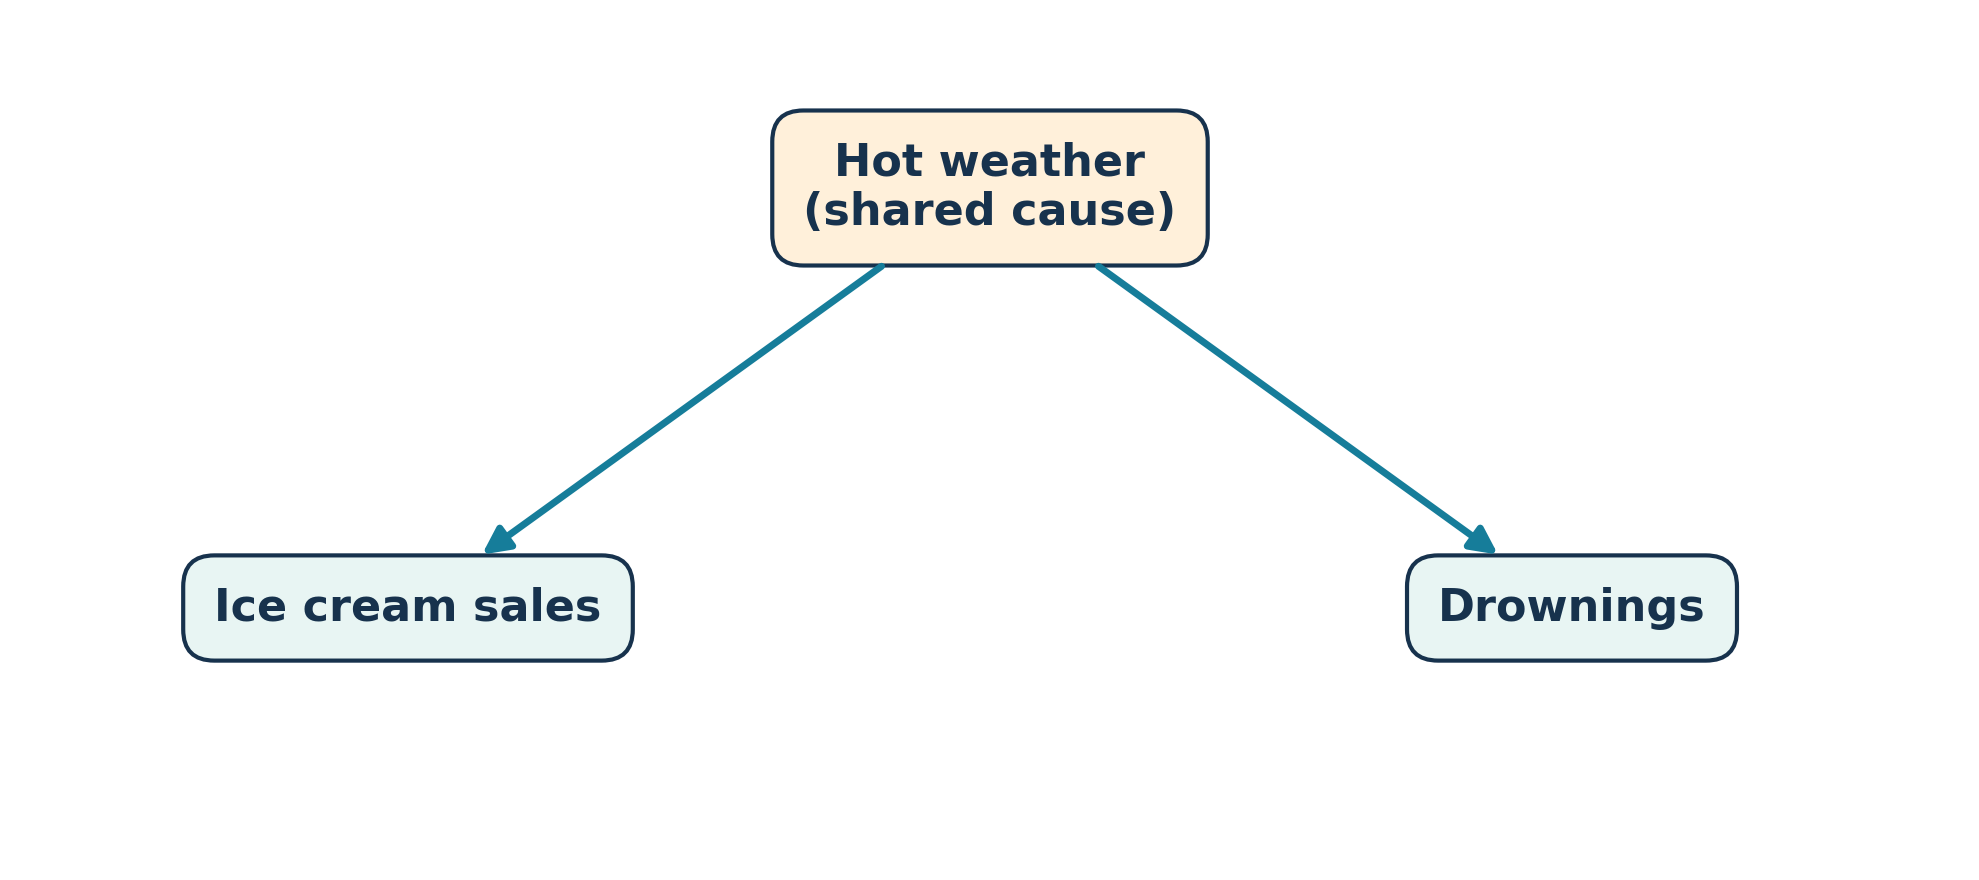

**They can move together because they share a cause: a confounder.**

A regression coefficient of **2** alone does not establish that
increasing X by one unit will **cause** Y to increase by two units.

---

## How Can We Establish Cause and Effect?

- **Randomized experiments:** Randomly assign an intervention and
  compare outcomes with a control group. Randomization balances
  potential confounders on average, supporting causal conclusions
  when the experiment is properly conducted and analyzed.

- **Why not always experiment?** Experiments can be expensive,
  impractical, or unethical, for example, deliberately introducing
  dangerous faults into vehicles on public roads.

- **Observational causal inference:** When randomization is unavailable,
  combine observed data with explicit causal assumptions and suitable
  methods to determine whether, and how, a causal effect can be estimated.

> **Today, we use observational data and a causal graph.
> This is one approach to causal inference, not the only one.**

## So, When Can We Say “X Causes Y”?

Even if a regression gives a coefficient of **2**, that alone does not mean:

> “Increasing X by one unit will cause Y to increase by two units.”

**Causal inference** combines data with explicit causal assumptions
to determine whether, and how, we can estimate that effect.

This takes us from **observing patterns** to asking **what would happen
if we changed something**.

### These different questions form the Ladder of Causation.

## The Ladder of Causation

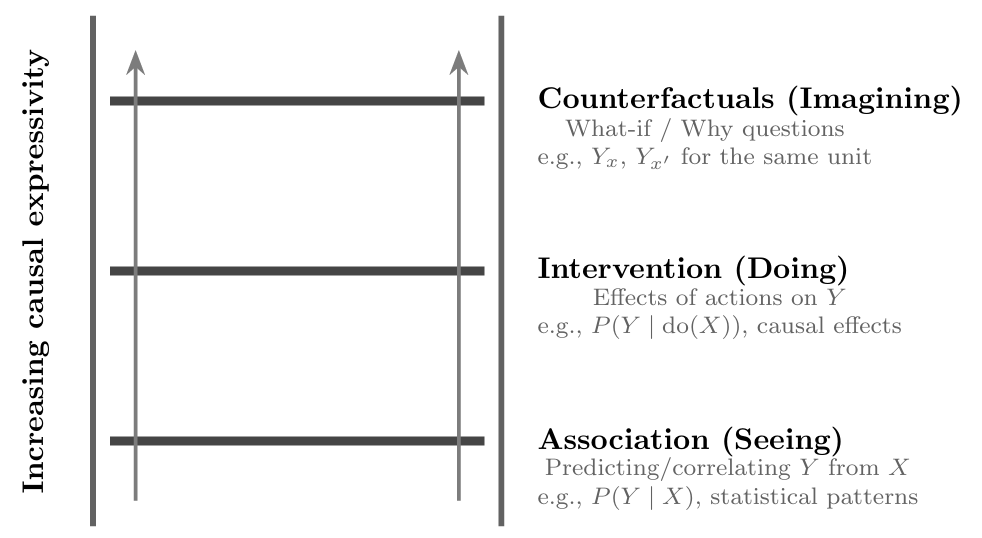

### Seeing → Doing → Imagining

| Level | Question | Example |
|---|---|---|
| **1. Association: Seeing** | What do we observe? | Do students who study longer score higher? |
| **2. Intervention: Doing** | What if we change something? | Would assigning two extra hours of study improve scores? |
| **3. Counterfactual: Imagining** | What if things had been different? | This student scored 60. What would they have scored had they studied longer? |

> **Observing a relationship does not, by itself, tell us the effect of changing it.**

Higher rungs require additional causal knowledge or assumptions, not just more data.

## Practical Demonstration: Causal Root Cause Analysis

We will investigate why a website became unusually slow and identify
the responsible service using **causal root cause analysis (RCA)**.

We will use **DoWhy**, a Python library that organizes causal effect
analysis into four stages: **Model, Identify, Estimate, and Refute**.

1. **Model:** Construct a causal graph describing how service latencies
   influence one another. This makes our assumptions about delay
   propagation explicit.

2. **Identify:** Determine whether the causal effect of interest can
   be recovered from observational data under the assumed graph,
   and which variables, if any, require adjustment.

3. **Estimate:** Use statistical methods to calculate the effect of
   changing a service’s latency on website latency.

4. **Refute:** Challenge the estimate using robustness checks.
   These can reveal weaknesses, but passing them does not prove
   the causal assumptions are correct.

We will then use a fitted causal model to attribute an abnormal
request’s latency to potential sources, distinguishing the origin
of the problem from its propagated effects.

**Association alone could flag unusual measurements and rank services
linked to the slowdown.** However, a service may be strongly associated
with the problem because it inherited a delay, not because it originated
it. Association alone cannot establish whether changing that service
would improve website performance.

## The System: An Online Shop

When a customer places an order, several services work together:

- **Authentication Service:** verifies the customer’s identity.
- **Product Service:** retrieves product information and shipping costs.
- **Caching Service:** provides stored product information, reducing database access.
- **Order Service:** processes the order.
- **Databases:** supply customer, product, and order information.

The website waits for the required work to finish before displaying
the order confirmation.

**Latency** is the time taken to complete a request. In this example,
a service’s measured latency includes time spent waiting for services
it depends on.

> **One slow component can make several other components appear slow.**

Our dataset contains **one row per simulated request** and
**one column per service’s latency**, measured in seconds.

In [ ]:
# Layered view of the online shop: databases at the bottom, the website at the top.
TIERS = {
    "Website": 4.0, "www": 3.2,
    "API": 2.4, "Auth Service": 2.4,
    "Product Service": 1.6, "Order Service": 1.6,
    "Caching Service": 0.8, "Shipping Cost Service": 0.8,
    "Product DB": 0.0, "Customer DB": 0.0, "Order DB": 0.0,
}
X_POS = {
    "Website": 0, "www": 0, "API": -0.6, "Auth Service": 1.2,
    "Product Service": -1.2, "Order Service": 0.6,
    "Caching Service": -1.8, "Shipping Cost Service": -0.6,
    "Product DB": -1.8, "Customer DB": 0.6, "Order DB": 1.8,
}
POS = {n: (X_POS[n], TIERS[n]) for n in TIERS}

EDGES = [
    ("www", "Website"), ("Auth Service", "www"), ("API", "www"),
    ("Customer DB", "Auth Service"), ("Customer DB", "API"),
    ("Product Service", "API"), ("Auth Service", "API"), ("Order Service", "API"),
    ("Shipping Cost Service", "Product Service"), ("Caching Service", "Product Service"),
    ("Product DB", "Caching Service"), ("Customer DB", "Product Service"),
    ("Order DB", "Order Service"),
]


def draw_system(graph, highlight=None, title=None, ax=None):
    """Draw the service graph; `highlight` maps node -> color."""
    highlight = highlight or {}
    ax = ax or plt.subplots(figsize=(9, 6.5))[1]
    colors = [highlight.get(n, "#DCEBF5" if "DB" not in n else "#EDEFF2") for n in graph]
    nx.draw_networkx_edges(graph, POS, ax=ax, edge_color=GRAY, arrowsize=16,
                           node_size=2600, connectionstyle="arc3,rad=0.04")
    nx.draw_networkx_nodes(graph, POS, ax=ax, node_color=colors, node_size=2600,
                           edgecolors=NAVY, linewidths=1.2)
    nx.draw_networkx_labels(graph, POS, ax=ax, font_size=8,
                            labels={n: n.replace(" ", "\n") for n in graph})
    ax.set_title(title or "", fontsize=12, color=NAVY)
    ax.axis("off")
    return ax


draw_system(nx.DiGraph(EDGES),
            title="Online shop: arrows show who waits for whom (delay flows upward)")
plt.show()

## Defining the Causal Question

The first step in causal inference is to **define the causal question**:
what do we want to change, and which outcome do we want to understand?

For this demonstration, we ask:

> **What is the causal effect of Caching Service latency on Website latency?**

In other words, if we deliberately changed the Caching Service’s latency,
how would the Website’s latency change on average?

- **Treatment (X):** Caching Service latency.
- **Outcome (Y):** Website latency.

To investigate this question, we begin with data generated under
**normal operating conditions**. There is no injected fault,
although service latencies naturally vary between requests.

- **Each row:** one simulated request.
- **Each column:** a service’s latency in seconds.

**We are not diagnosing a fault yet.** We are studying normal behavior
and will use the data together with a causal graph to estimate the effect.

Later, we will introduce an abnormal request and investigate
which service’s abnormal behavior explains the website slowdown.

In [ ]:
normal_data = load_data("rca_microservice_architecture_latencies.csv")

print(f"Number of requests: {normal_data.shape[0]:,}")
print(f"Number of service latency variables: {normal_data.shape[1]}")
display(normal_data.head())

# Association view: how strongly does each service co-move with Website latency?
corr = normal_data.corr()["Website"].drop("Website").sort_values()
ax = corr.plot.barh(color=BLUE, figsize=(7, 4))
ax.set_xlabel("Pearson correlation with Website latency")
ax.set_title("Association only: Caching Service looks unimportant (r = %.2f)"
             % corr["Caching Service"], color=NAVY)
plt.tight_layout(); plt.show()

> **Notice.** Under normal operation, Caching Service latency is only weakly correlated with
> Website latency. A purely associational analysis would rank it near the bottom.
> Keep this in mind: the causal analysis below asks a different question,
> namely what would happen *if we changed it*.

## Stage 1: Model the Causal Graph

The first stage of our causal inference pipeline is to construct a
**causal graph**, representing our assumptions about which variables
directly influence others.

We can obtain this graph through:

- **Domain knowledge:** use knowledge of the system’s architecture
  and how its components interact.
- **Causal discovery:** use algorithms to learn possible causal
  structures from data under specific assumptions.
- **A combination of both:** combine data-driven discovery with
  expert knowledge and system constraints.

**Here, we use domain knowledge of the simulated system and its
data-generating process to specify the graph.**

**In this tutorial, we use a causal graph to make our assumptions explicit.**
It represents how delays propagate between services and guides
whether, and how, we can estimate the causal effect from observational data.

In [ ]:
causal_graph = nx.DiGraph(EDGES)

draw_system(causal_graph,
            highlight={"Caching Service": ORANGE, "Website": "#7FC8A9"},
            title="Causal graph: treatment (orange) and outcome (green)")
plt.show()

print("Directed paths from Caching Service to Website:")
for path in nx.all_simple_paths(causal_graph, "Caching Service", "Website"):
    print("  " + " → ".join(path))

## Stage 2: Identification

Identification determines whether, and how, the causal effect can
be expressed using observational data under our causal assumptions.
It gives us an **estimand**: a mathematical expression for the effect,
not yet a numerical estimate.

Three common identification approaches are:

- **Backdoor adjustment:** Adjust for an appropriate set of variables
  to block confounding between the treatment and outcome.

- **Frontdoor adjustment:** Use mediating variables that transmit
  the treatment’s effect to the outcome, under specific conditions
  that can allow identification despite unmeasured confounding.

- **Instrumental variables:** Use a variable that influences the
  treatment, affects the outcome only through that treatment,
  and is independent of unmeasured causes of the outcome.
  Additional assumptions determine which effect is identified.

**Each approach requires its own assumptions; they are not interchangeable.**

In [ ]:
# DoWhy reads the graph in GML format.
graph_gml = "\n".join(nx.generate_gml(causal_graph))

model = CausalModel(
    data=normal_data,
    treatment="Caching Service",
    outcome="Website",
    graph=graph_gml,
)

estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(estimand)

### Interpreting the Identification Output

Under the supplied causal graph, DoWhy identifies **all three approaches
(backdoor, instrumental variables, and frontdoor) as available**:

- **Backdoor:** The effect is identifiable without adjusting for confounders.
- **Instrumental variables:** Product DB provides an instrument for Caching Service latency.
- **Frontdoor:** Product Service, API, and www provide the mediating variables through which the effect propagates.

The output also reports **general adjustment**, which gives the same
expression as backdoor adjustment in this example.

**These identification results hold under the graph and the assumptions
listed in the output.** We will proceed with backdoor adjustment,
the simplest available approach here.

## Stage 3: Estimation

Having identified the causal effect, we now use the data to
**estimate its numerical value**.

We begin with **linear regression**, using the backdoor estimand.
The fitted model estimates how much Website latency changes,
on average, for a one-second increase in Caching Service latency.

**The causal interpretation comes from our assumptions and
identification strategy, not from regression alone.**

In [ ]:
estimate_lr = model.estimate_effect(
    identified_estimand=estimand,
    method_name="backdoor.linear_regression",
    control_value=0,
    treatment_value=1,
)

print(f"Estimated causal effect (linear regression): {estimate_lr.value:.4f}")

### Interpreting the Estimate

The estimated effect is **0.6762**.

Under our causal assumptions and fitted linear model, a **one-second
increase in Caching Service latency** is estimated to increase
**Website latency by approximately 0.676 seconds on average**.

This is an estimated effect, not a percentage or a guarantee
for every individual request.


### Alternative Estimator: Double Machine Learning

DML uses machine learning to model the outcome and treatment,
then estimates the treatment effect after accounting for those
modeled relationships.

We will compare its estimate with linear regression’s **0.6762**.
Similar results suggest agreement across estimators, but do not
prove that our causal assumptions are correct.

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LassoCV

estimate_dml = model.estimate_effect(
    identified_estimand=estimand,
    method_name="backdoor.econml.dml.DML",
    control_value=0,
    treatment_value=1,
    method_params={
        "init_params": {
            "model_y": GradientBoostingRegressor(random_state=42),
            "model_t": GradientBoostingRegressor(random_state=42),
            "model_final": LassoCV(fit_intercept=False),
            "random_state": 42,
        },
        "fit_params": {},
    },
)

print(f"Linear regression:       {estimate_lr.value:.4f}")
print(f"Double Machine Learning: {estimate_dml.value:.4f}")

## Stage 4: Refutation: Stress-Testing the Estimate

Refutation tests try to **“break” our result through controlled changes**
to the data or model. They assess robustness, not whether our causal
assumptions are true.

- **Random common cause:** Add an independent random variable as a
  potential confounder in the model. Because it carries no relevant
  information, the estimate should remain close to the original.
- **Placebo treatment:** Randomly permute the treatment values.
  The estimated effect should be close to zero.
- **Data subset:** Re-estimate using random subsets of observations.
  The estimates should remain reasonably similar.
- **Bootstrap:** Resample observations with replacement and re-estimate.
  Large variation indicates sensitivity to sampling.

> **Passing these checks supports robustness, but does not prove causality
> or rule out unmeasured confounding.**

In [ ]:
# 1. Random common cause: add an independent random confounder.
refute_random = model.refute_estimate(
    estimand, estimate_lr,
    method_name="random_common_cause",
    num_simulations=10, random_state=42,
)
print(refute_random)

In [ ]:
# 2. Placebo treatment: permute the treatment; the effect should vanish.
refute_placebo = model.refute_estimate(
    estimand, estimate_lr,
    method_name="placebo_treatment_refuter",
    placebo_type="permute",
    num_simulations=30, random_state=42,
)
print(refute_placebo)

In [ ]:
# 3. Data subset: re-estimate on random 80% subsets.
refute_subset = model.refute_estimate(
    estimand, estimate_lr,
    method_name="data_subset_refuter",
    subset_fraction=0.8,
    num_simulations=30,
    random_state=np.random.RandomState(42),
    n_jobs=1,
)
print(refute_subset)

In [ ]:
# 4. Bootstrap: resample with replacement and re-estimate.
refute_boot = model.refute_estimate(
    estimand, estimate_lr,
    method_name="bootstrap_refuter",
    num_simulations=30,
    random_state=np.random.RandomState(42),
    n_jobs=1,
)
print(refute_boot)

In [ ]:
# Summary of all four robustness checks.
refuters = {
    "Random common cause": (refute_random, "≈ original"),
    "Placebo treatment":   (refute_placebo, "≈ 0"),
    "Data subset (80%)":   (refute_subset, "≈ original"),
    "Bootstrap":           (refute_boot, "≈ original"),
}
summary = pd.DataFrame({
    "Original effect": [r.estimated_effect for r, _ in refuters.values()],
    "New effect":      [r.new_effect for r, _ in refuters.values()],
    "Expected":        [e for _, e in refuters.values()],
    "p-value":         [r.refutation_result["p_value"] for r, _ in refuters.values()],
}, index=refuters.keys())
display(summary.round(4))

## Root Cause Analysis: Investigating an Abnormal Request

So far, we estimated a causal effect using normal-operation data.
We now investigate a request with unusually high Website latency.

> **Which service’s abnormal behavior explains this slowdown?**

First, we compare the request with normal behavior.
Large deviations identify symptoms, but do not by themselves
distinguish the source of a delay from its propagated effects.

We reuse the causal graph and normal-operation data, but now fit
a model of each service’s behavior. The earlier effect estimates
and refutation results are not inputs to this RCA analysis:
they answered a different causal question.

In [ ]:
outlier = load_data("rca_microservice_architecture_anomaly.csv")

print("Abnormal request:")
display(outlier)

comparison = pd.DataFrame({
    "Normal mean (s)": normal_data.mean(),
    "Abnormal request (s)": outlier.iloc[0],
})
comparison["Difference (s)"] = comparison["Abnormal request (s)"] - comparison["Normal mean (s)"]

print("\nComparison with normal operation (the naive symptom view):")
display(comparison.sort_values("Difference (s)", ascending=False).round(3))

## Fitting the Causal Model

The comparison shows where latencies increased, but some increases
may simply reflect delays inherited from other services.

To distinguish these, we need both **the causal graph** and
**a model of how each service’s latency depends on its parents**.

We fit these relationships using **normal-operation data**.
The abnormal request is reserved for the diagnosis.

Here, we use linear relationships with an additional noise term
for non-root services. This is an approximation: the simulated
system also contains nonlinear behavior.

In [ ]:
# Build a structural causal model on the same graph.
causal_model = gcm.StructuralCausalModel(causal_graph.copy())

for node in causal_model.graph.nodes:
    if causal_model.graph.in_degree(node) == 0:
        # Root services: learn their normal latency distributions.
        causal_model.set_causal_mechanism(node, gcm.EmpiricalDistribution())
    else:
        # Other services: latency = f(parents) + noise.
        causal_model.set_causal_mechanism(
            node, gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))

# Learn the mechanisms from normal operation only.
gcm.fit(causal_model, normal_data)
print("Causal model fitted using normal-operation data.")

## Attributing the Anomaly

We now use the fitted causal model to estimate how each service’s
behavior contributes to the **Website’s anomaly score**.

This accounts for delay propagation, rather than simply ranking
the largest latency increases.

**Larger positive scores indicate stronger contributions to the anomaly.
These scores are not measured in seconds.**

In [ ]:
np.random.seed(42)

attributions = gcm.attribute_anomalies(
    causal_model,
    target_node="Website",
    anomaly_samples=outlier.iloc[[0]],
)

attribution_scores = pd.Series(
    {service: np.asarray(score).item() for service, score in attributions.items()}
).sort_values(ascending=False)

print("Contributions to the Website anomaly score:")
display(attribution_scores.to_frame("Attribution score").round(3))

# Side by side: naive symptom ranking vs causal attribution.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

naive = comparison["Difference (s)"].sort_values()
ax1.barh(naive.index, naive.values,
         color=[ORANGE if v == naive.max() else GRAY for v in naive.values])
ax1.set_title("Naive view: largest latency increase", color=NAVY)
ax1.set_xlabel("Increase over normal mean (seconds)")

scores = attribution_scores.sort_values()
ax2.barh(scores.index, scores.values,
         color=[ORANGE if v == scores.max() else BLUE for v in scores.values])
ax2.axvline(0, color=NAVY, linewidth=1)
ax2.set_title("Causal view: contribution to anomaly score", color=NAVY)
ax2.set_xlabel("Attribution score (not seconds)")

plt.tight_layout(); plt.show()

## Diagnosis: Caching Service Is the Leading Contributor

**Caching Service has the largest positive attribution score (3.707)**,
making it the primary source to investigate under our fitted causal model.

- **Product Service (1.790)** and **Order Service (0.666)** also receive
  positive contributions. These do not necessarily indicate separate
  faults; imperfect modeling can affect the allocation of scores.
- **Customer DB (−2.719)** offsets part of the Website anomaly
  according to the model.
- These values are **contributions to an anomaly score, not seconds
  of delay or probabilities of being the root cause**.

Although several services became slower, the causal analysis points
primarily to **Caching Service**, rather than simply selecting
the service with the largest observed latency increase.

**Next operational step:** inspect the Caching Service and verify
whether correcting its abnormal behavior resolves the slowdown.

## Scenario 2: Investigating a Persistent Slowdown

Previously, we explained **one abnormal request**.
Now, we investigate **1,000 requests during degraded operation**.

> **Which service’s changed behavior explains the increase
> in average Website latency?**

We will compare normal and degraded operation, then use
**distribution-change attribution** to explain the change in the mean.

In [ ]:
degraded_data = load_data("rca_microservice_architecture_anomaly_1000.csv")

print(f"Requests during degraded operation: {len(degraded_data):,}")
display(degraded_data.head())

mean_comparison = pd.DataFrame({
    "Normal mean (s)": normal_data.mean(),
    "Degraded mean (s)": degraded_data.mean(),
})
mean_comparison["Increase (s)"] = mean_comparison["Degraded mean (s)"] - mean_comparison["Normal mean (s)"]
display(mean_comparison.sort_values("Increase (s)", ascending=False).round(3))

## Explaining the Increase in Average Latency

We now use **distribution-change attribution** to estimate how changes
in each service’s causal mechanism contributed to the increase
in average Website latency.

Unlike the single-request anomaly scores, **these contributions
are measured in seconds**, because we are explaining a change in the mean.

In [ ]:
np.random.seed(42)

change_attributions = gcm.distribution_change(
    causal_model,
    normal_data,
    degraded_data,
    target_node="Website",
    difference_estimation_func=lambda before, after: np.mean(after) - np.mean(before),
)

change_scores = pd.Series(change_attributions,
                          name="Contribution to mean change (s)").sort_values(ascending=False)
display(change_scores.to_frame().round(3))

observed_change = degraded_data["Website"].mean() - normal_data["Website"].mean()
print(f"Observed increase in mean Website latency: {observed_change:.3f} s")
print(f"Sum of estimated contributions:            {change_scores.sum():.3f} s")
print(f"Share attributed to Caching Service:       "
      f"{change_scores['Caching Service'] / observed_change:.0%}")

fig, ax = plt.subplots(figsize=(9, 5.5))
s = change_scores.sort_values()
ax.barh(s.index, s.values, color=[ORANGE if v == s.max() else BLUE for v in s.values])
ax.axvline(0, color=NAVY, linewidth=1)
ax.set_xlabel("Contribution to change in mean Website latency (seconds)")
ax.set_title("Which services explain the persistent slowdown?", color=NAVY)
plt.tight_layout(); plt.show()

## Diagnosis: Caching Service Explains Most of the Slowdown

Average Website latency increased by **1.932 seconds**.
The model attributes **1.866 seconds** to a change in the
**Caching Service’s mechanism**, approximately **97% of the observed increase**.

Contributions from other services are small.
In particular, **Product Service contributes approximately zero**:
its latency increased, but the model attributes that increase
primarily to an inherited delay rather than a change in its own mechanism.

The estimated contributions do not exactly reproduce the observed
increase because they rely on fitted models and sampling.

> **Both analyses point to Caching Service: it is the leading contributor
> to the single-request anomaly and the persistent slowdown.**

## What We Have Demonstrated

| Task | Question | Our result |
|---|---|---|
| **Causal effect estimation** | How would changing Caching Service latency affect Website latency? | Estimated average increase of **0.68–0.75 seconds** per additional second, under our fitted models and assumptions. |
| **Single-request RCA** | Which service best explains this abnormal request? | **Caching Service** had the largest positive anomaly attribution. |
| **Persistent-slowdown RCA** | Which mechanism change explains the increase in average latency? | **Caching Service** contributed approximately **1.866 seconds** of the observed **1.932-second** increase. |

**Association identifies patterns. Causal analysis uses explicit assumptions
about the system to estimate intervention effects and explain observed problems.**

Our diagnosis points to **Caching Service as the primary investigation target**.
In practice, we would inspect its behavior, apply a targeted correction,
and check whether Website performance recovers.

> **A causal diagnosis is supported by the model and data;
> it should also be checked against system evidence and interventions.**

## Try It Yourself

1. **Change the question.** Re-run Stage 2 and Stage 3 with `treatment="Customer DB"`.
   Why does DoWhy now report a different set of identification strategies?
2. **Break an assumption.** Delete the edge `("Caching Service", "Product Service")` from `EDGES`,
   refit the structural causal model, and repeat the anomaly attribution.
   What happens to the diagnosis when the graph is wrong?
3. **Nonlinear mechanisms.** Replace `gcm.ml.create_linear_regressor()` with
   `gcm.ml.create_hist_gradient_boost_regressor()`. Do the attribution scores become cleaner?
4. **Uncertainty.** Wrap `gcm.distribution_change` in `gcm.confidence_intervals(...)`
   (see the DoWhy documentation) and report a 95% interval for the Caching Service contribution.

## Tutorial Source

Adapted from the DoWhy example:
[Finding the Root Cause of Elevated Latencies in a Microservice Architecture](https://www.pywhy.org/dowhy/v0.13/example_notebooks/gcm_rca_microservice_architecture.html).


---

### Credits

Tutorial prepared by **Ousman Khan**, **AI for Smart Mobility Lab (AI4SM)**, KFUPM,
for **ISE 518: Data Analytics for Reliability and Maintenance**, taught by **Dr. Alaa Khamis**,
Industrial and Systems Engineering Department, King Fahd University of Petroleum & Minerals.

Data: simulated microservice latencies from the DoWhy project (PyWhy), MIT License.